# Image-Classification-Deep-Learning

In [6]:
# import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt



In [7]:
df = pd.read_csv(r"C:\Users\Dell\Image-Classification-Deep-Learning\data\digits_image_classification.csv")

df.head()

,pixel_0,pixel_1,pixel_2,pixel_3,pixel_4,pixel_5,pixel_6,pixel_7,pixel_8,pixel_9,...,pixel_55,pixel_56,pixel_57,pixel_58,pixel_59,pixel_60,pixel_61,pixel_62,pixel_63,label
0,0.0,0.0,5.0,13.0,9.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,6.0,13.0,10.0,0.0,0.0,0.0,0
1,0.0,0.0,0.0,12.0,13.0,5.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,11.0,16.0,10.0,0.0,0.0,1
2,0.0,0.0,0.0,4.0,15.0,12.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,3.0,11.0,16.0,9.0,0.0,2
3,0.0,0.0,7.0,15.0,13.0,1.0,0.0,0.0,0.0,8.0,...,0.0,0.0,0.0,7.0,13.0,13.0,9.0,0.0,0.0,3
4,0.0,0.0,0.0,1.0,11.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,2.0,16.0,4.0,0.0,0.0,4


In [8]:
df.info()
df.describe()
df.isnull().sum()
df.columns


<class 'pandas.DataFrame'>
RangeIndex: 1797 entries, 0 to 1796
Data columns (total 65 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   pixel_0   1797 non-null   float64
 1   pixel_1   1797 non-null   float64
 2   pixel_2   1797 non-null   float64
 3   pixel_3   1797 non-null   float64
 4   pixel_4   1797 non-null   float64
 5   pixel_5   1797 non-null   float64
 6   pixel_6   1797 non-null   float64
 7   pixel_7   1797 non-null   float64
 8   pixel_8   1797 non-null   float64
 9   pixel_9   1797 non-null   float64
 10  pixel_10  1797 non-null   float64
 11  pixel_11  1797 non-null   float64
 12  pixel_12  1797 non-null   float64
 13  pixel_13  1797 non-null   float64
 14  pixel_14  1797 non-null   float64
 15  pixel_15  1797 non-null   float64
 16  pixel_16  1797 non-null   float64
 17  pixel_17  1797 non-null   float64
 18  pixel_18  1797 non-null   float64
 19  pixel_19  1797 non-null   float64
 20  pixel_20  1797 non-null   float64
 21  pi

Index(['pixel_0', 'pixel_1', 'pixel_2', 'pixel_3', 'pixel_4', 'pixel_5',
       'pixel_6', 'pixel_7', 'pixel_8', 'pixel_9', 'pixel_10', 'pixel_11',
       'pixel_12', 'pixel_13', 'pixel_14', 'pixel_15', 'pixel_16', 'pixel_17',
       'pixel_18', 'pixel_19', 'pixel_20', 'pixel_21', 'pixel_22', 'pixel_23',
       'pixel_24', 'pixel_25', 'pixel_26', 'pixel_27', 'pixel_28', 'pixel_29',
       'pixel_30', 'pixel_31', 'pixel_32', 'pixel_33', 'pixel_34', 'pixel_35',
       'pixel_36', 'pixel_37', 'pixel_38', 'pixel_39', 'pixel_40', 'pixel_41',
       'pixel_42', 'pixel_43', 'pixel_44', 'pixel_45', 'pixel_46', 'pixel_47',
       'pixel_48', 'pixel_49', 'pixel_50', 'pixel_51', 'pixel_52', 'pixel_53',
       'pixel_54', 'pixel_55', 'pixel_56', 'pixel_57', 'pixel_58', 'pixel_59',
       'pixel_60', 'pixel_61', 'pixel_62', 'pixel_63', 'label'],
      dtype='str')

In [10]:
# X and y values separation
x = df.drop('label', axis=1)
y = df['label']
print(x.shape, y.shape)

(1797, 64) (1797,)


In [12]:
# train test split
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)  

X_train shape: (1437, 64)
X_test shape: (360, 64)
y_train shape: (1437,)
y_test shape: (360,)


In [13]:
X_train = X_train / 16.0
Y_train = y_train / 16.0
print("Minimun:", X_train.min())
print("Maximum:", X_train.max())


Minimun: pixel_0     0.0
pixel_1     0.0
pixel_2     0.0
pixel_3     0.0
pixel_4     0.0
           ... 
pixel_59    0.0
pixel_60    0.0
pixel_61    0.0
pixel_62    0.0
pixel_63    0.0
Length: 64, dtype: float64
Maximum: pixel_0     0.0
pixel_1     0.5
pixel_2     1.0
pixel_3     1.0
pixel_4     1.0
           ... 
pixel_59    1.0
pixel_60    1.0
pixel_61    1.0
pixel_62    1.0
pixel_63    1.0
Length: 64, dtype: float64


In [17]:
# create a model ANN
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

model = Sequential([
    Dense(128, activation="relu", input_shape=(64,)),
    Dense(64, activation="relu"),
    Dense(10, activation="softmax")
])

model.summary()



c:\Users\Dell\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,226 (67.29 KB)

 Trainable params: 17,226 (67.29 KB)

 Non-trainable params: 0 (0.00 B)

In [18]:
# compile the model 
model.compile(
    optimizer='rmsprop',
    loss = "sparse_categorical_crossentropy",
    metrics = ["accuracy"]
)

In [19]:
# model training
history = model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.2
)


Epoch 1/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - accuracy: 0.5701 - loss: 1.7831 - val_accuracy: 0.7743 - val_loss: 1.3245
Epoch 2/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8285 - loss: 0.9751 - val_accuracy: 0.8646 - val_loss: 0.6821
Epoch 3/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.9034 - loss: 0.5404 - val_accuracy: 0.8785 - val_loss: 0.4430
Epoch 4/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9304 - loss: 0.3529 - val_accuracy: 0.8889 - val_loss: 0.3497
Epoch 5/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9434 - loss: 0.2577 - val_accuracy: 0.9306 - val_loss: 0.2687
Epoch 6/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9574 - loss: 0.2034 - val_accuracy: 0.9306 - val_loss: 0.2350
Epoch 7/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9652 - loss: 0.1671 - val_accuracy: 0.9444 - val_loss: 0.2106
Epoch 8/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9661 - loss: 0.1431 - val_accuracy: 0.9410 - val_lo

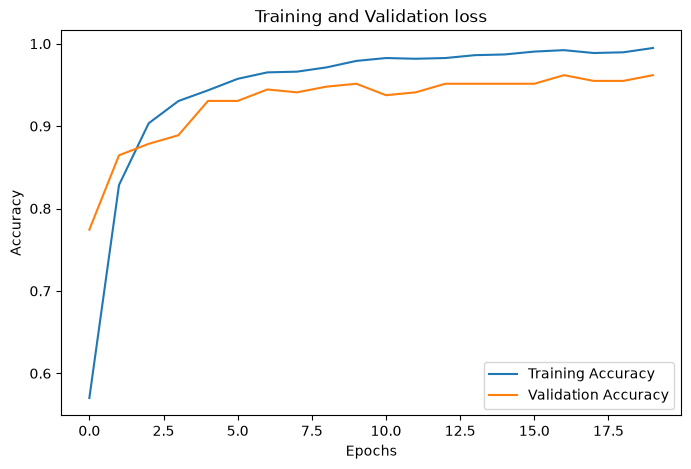

In [21]:
# graph the training and validation accuracy
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Training and Validation loss')
plt.legend()
plt.show()

In [22]:
test_loss, test_accuracy = model.evaluate(X_test, y_test,verbose=0)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

Test Loss: 0.7422307133674622
Test Accuracy: 0.9666666388511658


In [23]:
# predict the test data
y_pred_prob = model.predict(X_test)

y_pred = np.argmax(y_pred_prob, axis=1)

print("Actual    :",y_test.values[:10])
print("Predicted :",y_pred[:10])


12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
Actual    : [6 9 3 7 2 1 5 2 5 2]
Predicted : [6 9 3 7 2 1 5 2 5 2]


In [24]:
results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

results.head(20)

,Actual,Predicted
0,6,6
1,9,9
2,3,3
3,7,7
4,2,2
5,1,1
6,5,5
7,2,2
8,5,5
9,2,2


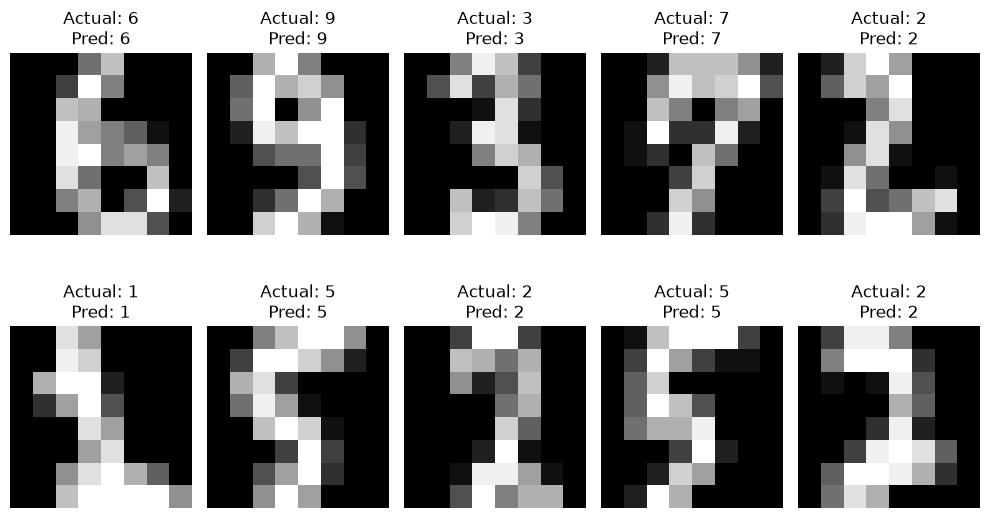

In [25]:
plt.figure(figsize=(10, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    image = X_test.iloc[i].values.reshape(8, 8)

    plt.imshow(image, cmap="gray")
    plt.title(f"Actual: {y_test.iloc[i]}\nPred: {y_pred[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()


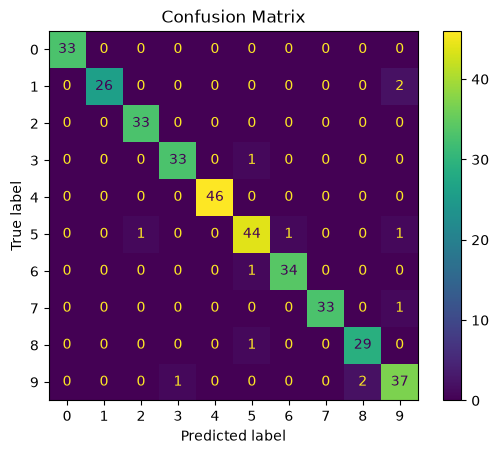

In [26]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()

plt.title("Confusion Matrix")
plt.show()

In [28]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

model.save("digit_classifier.keras")

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        33
           1       1.00      0.93      0.96        28
           2       0.97      1.00      0.99        33
           3       0.97      0.97      0.97        34
           4       1.00      1.00      1.00        46
           5       0.94      0.94      0.94        47
           6       0.97      0.97      0.97        35
           7       1.00      0.97      0.99        34
           8       0.94      0.97      0.95        30
           9       0.90      0.93      0.91        40

    accuracy                           0.97       360
   macro avg       0.97      0.97      0.97       360
weighted avg       0.97      0.97      0.97       360



In [29]:
import os

print(os.path.exists("digit_classifier.keras"))

True


In [30]:
from tensorflow.keras.models import load_model

loaded_model = load_model("digit_classifier.keras")

print("Model loaded successfully!")

Model loaded successfully!


In [31]:
index = 0

sample_image = X_test.iloc[index].values.reshape(1, 64)

probabilities = loaded_model.predict(sample_image, verbose=0)

predicted_digit = np.argmax(probabilities)

print("Actual Digit   :", y_test.iloc[index])
print("Predicted Digit:", predicted_digit)

Actual Digit   : 6
Predicted Digit: 6


In [32]:
index = 25

sample_image = X_test.iloc[index].values.reshape(1, 64)

probabilities = loaded_model.predict(sample_image, verbose=0)

predicted_digit = np.argmax(probabilities)

print("Actual Digit   :", y_test.iloc[index])
print("Predicted Digit:", predicted_digit)

Actual Digit   : 6
Predicted Digit: 6


In [33]:
print("Probabilities:")
print(probabilities[0])

Probabilities:
[0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]
